# Cancer survival prediction from frozen transcriptomic representations

## Introduction

This analysis tests whether a frozen Bridge representation retains censoring-aware prognostic information relative to PCA-128 and full raw expression.

## Data and endpoint

The cohort contains **9,668 patients**, **32 cancer types**, and **2,774 overall-survival events**. Every patient receives exactly one prediction from a Cox head that was not trained on that patient.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
HERE = Path.cwd()
if not (HERE / 'data').exists():
    HERE = Path('benchmarks/cancer_survival')
CACHE = HERE / 'data'
FIGURES = HERE / 'figures'
qa = json.loads((CACHE / 'package_validation.json').read_text())
assert qa['status'] == 'passed'
qa['status'], qa['prediction_rows_checked']

('passed', 58008)

## Methods

Bridge remains frozen. Scaling and PCA are fitted on training folds only. All representations use identical folds and outcomes and are tested with both linear Cox and a `[512,256]` Cox MLP. Concordance is aggregated within held-out folds. Cancer-specific intervals use 1,000 patient-level bootstrap draws retaining fold membership.

In [2]:
metrics = pd.read_csv(CACHE / 'survival_head_factorial_metrics.csv')
table = metrics.pivot(index='representation', columns='head', values='oof_c_index').loc[['Bridge 45.6M','PCA-128','Full raw expression']]
display(table.round(4))

head,"Cox MLP [512,256]",Linear Cox
representation,,
Bridge 45.6M,0.7580,0.7589
PCA-128,0.7638,0.7615
Full raw expression,0.7590,0.7533


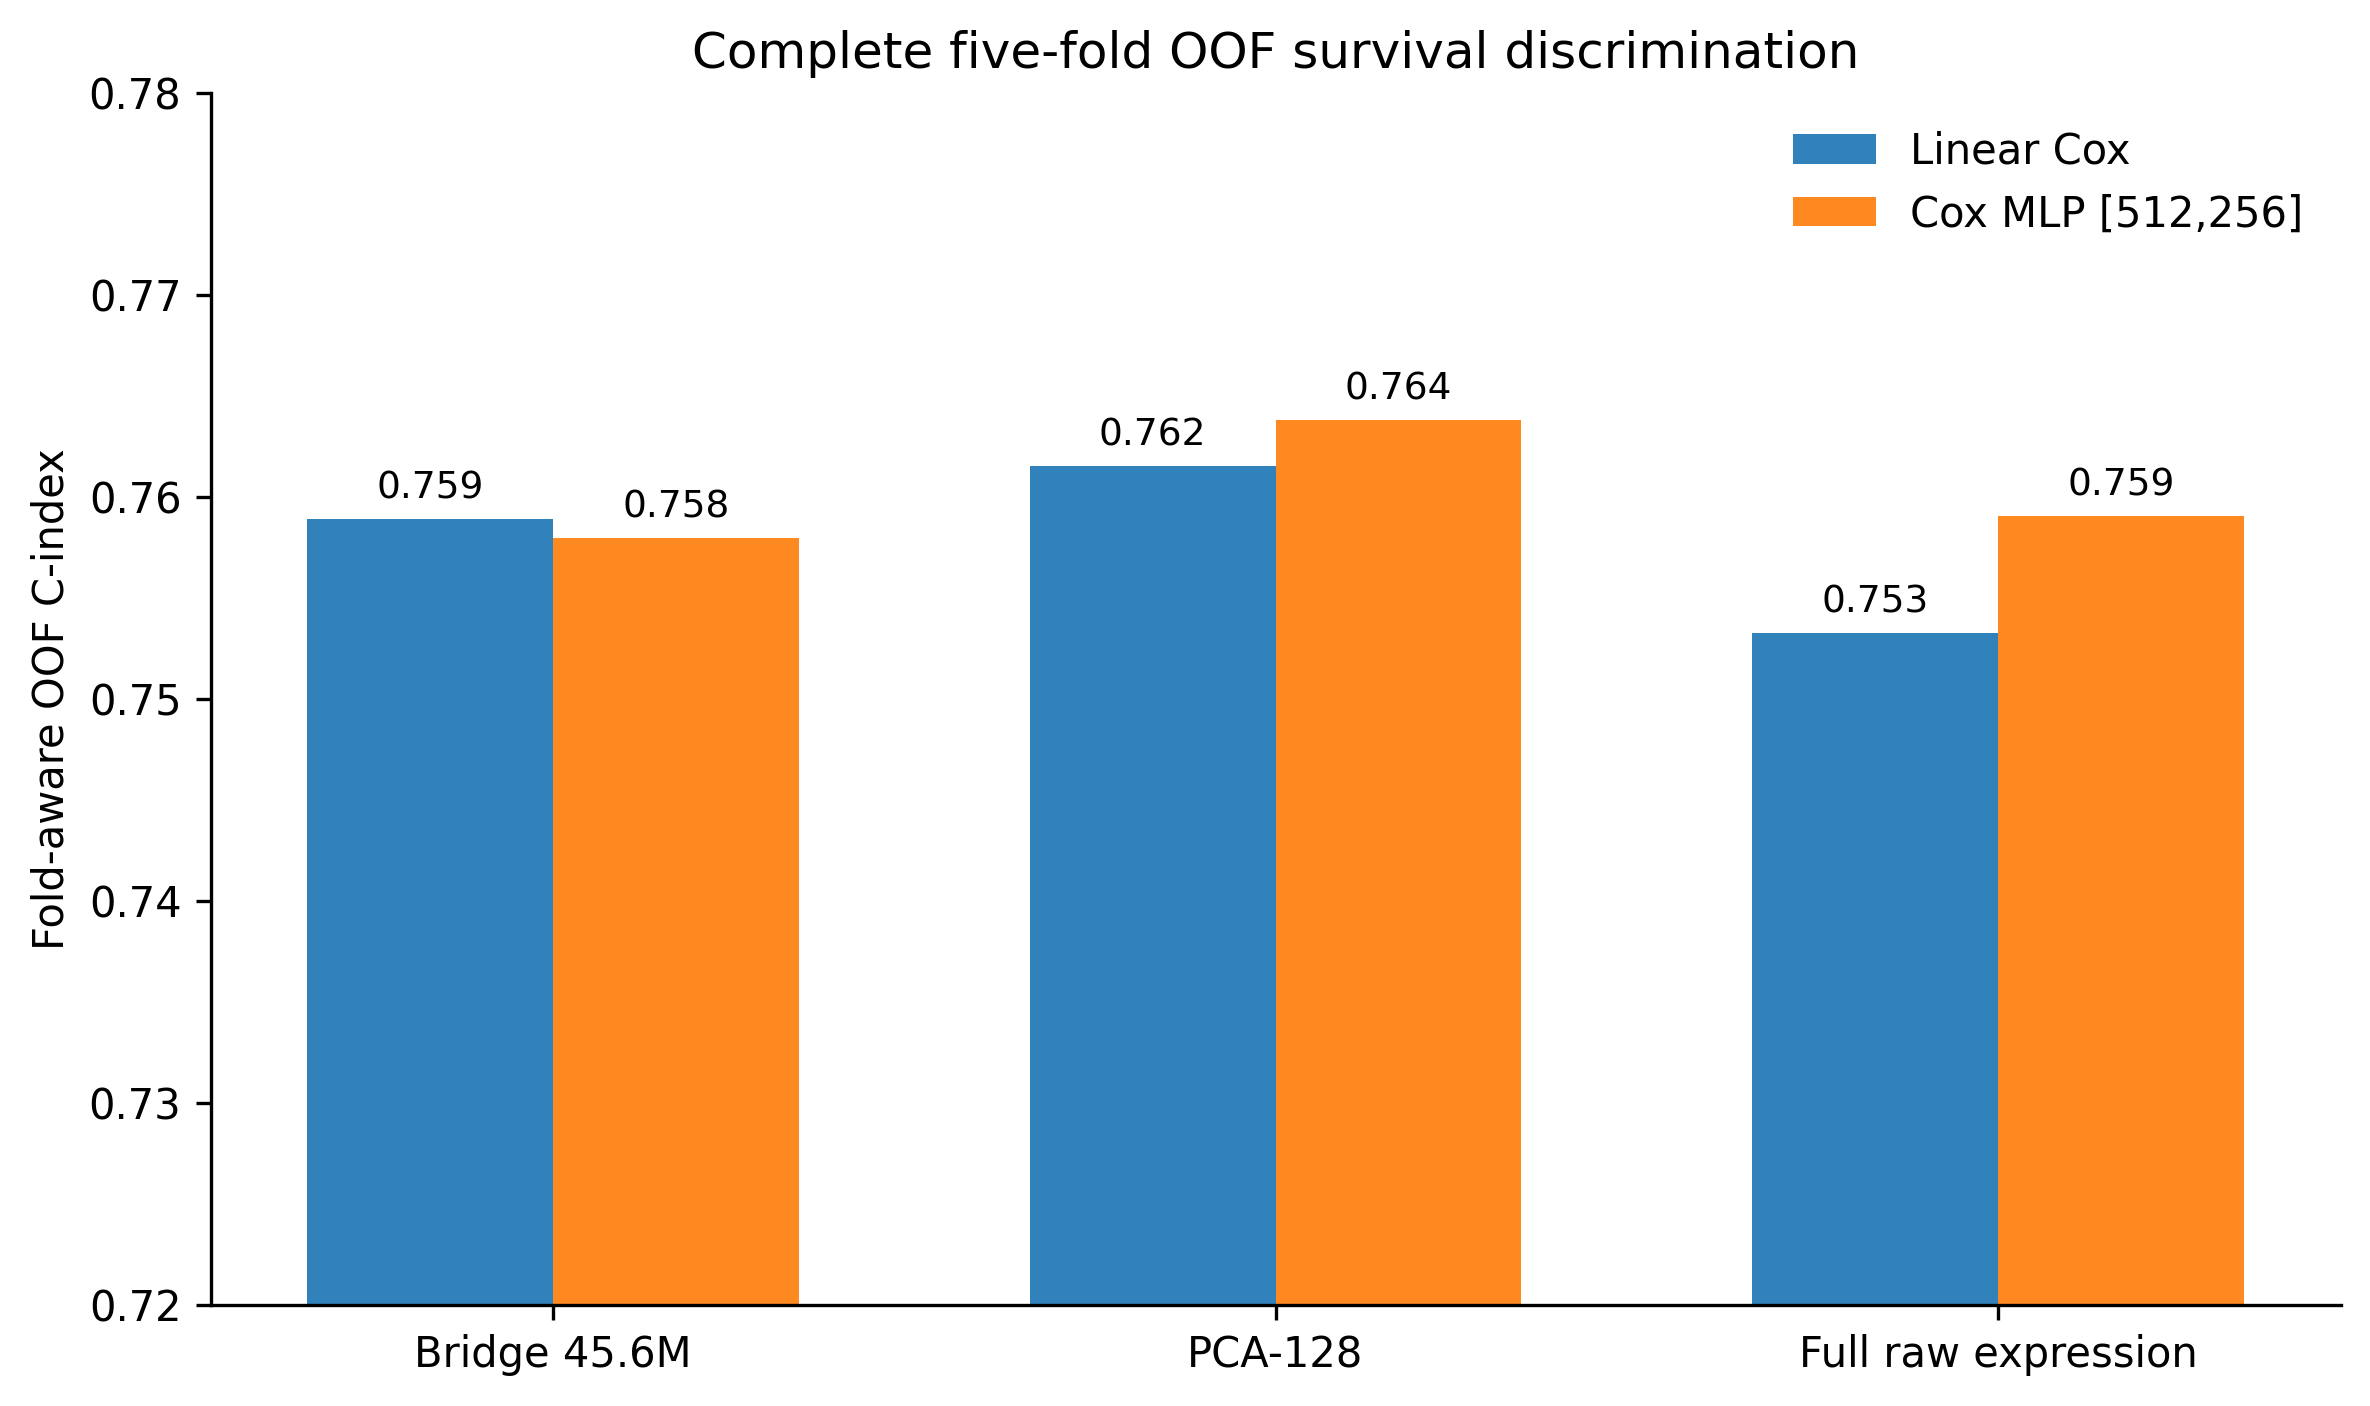

In [3]:
display(Image(filename=str(FIGURES / 'oof_survival_overall.png')))

Bridge achieves C-index **0.7589** with linear Cox and **0.7580** with the Cox MLP. PCA-128 achieves 0.7615/0.7638 and full expression 0.7533/0.7590. Bridge is nearly head-insensitive, and no representation or head contrast remains significant after multiplicity correction.

## Within-cancer survival discrimination

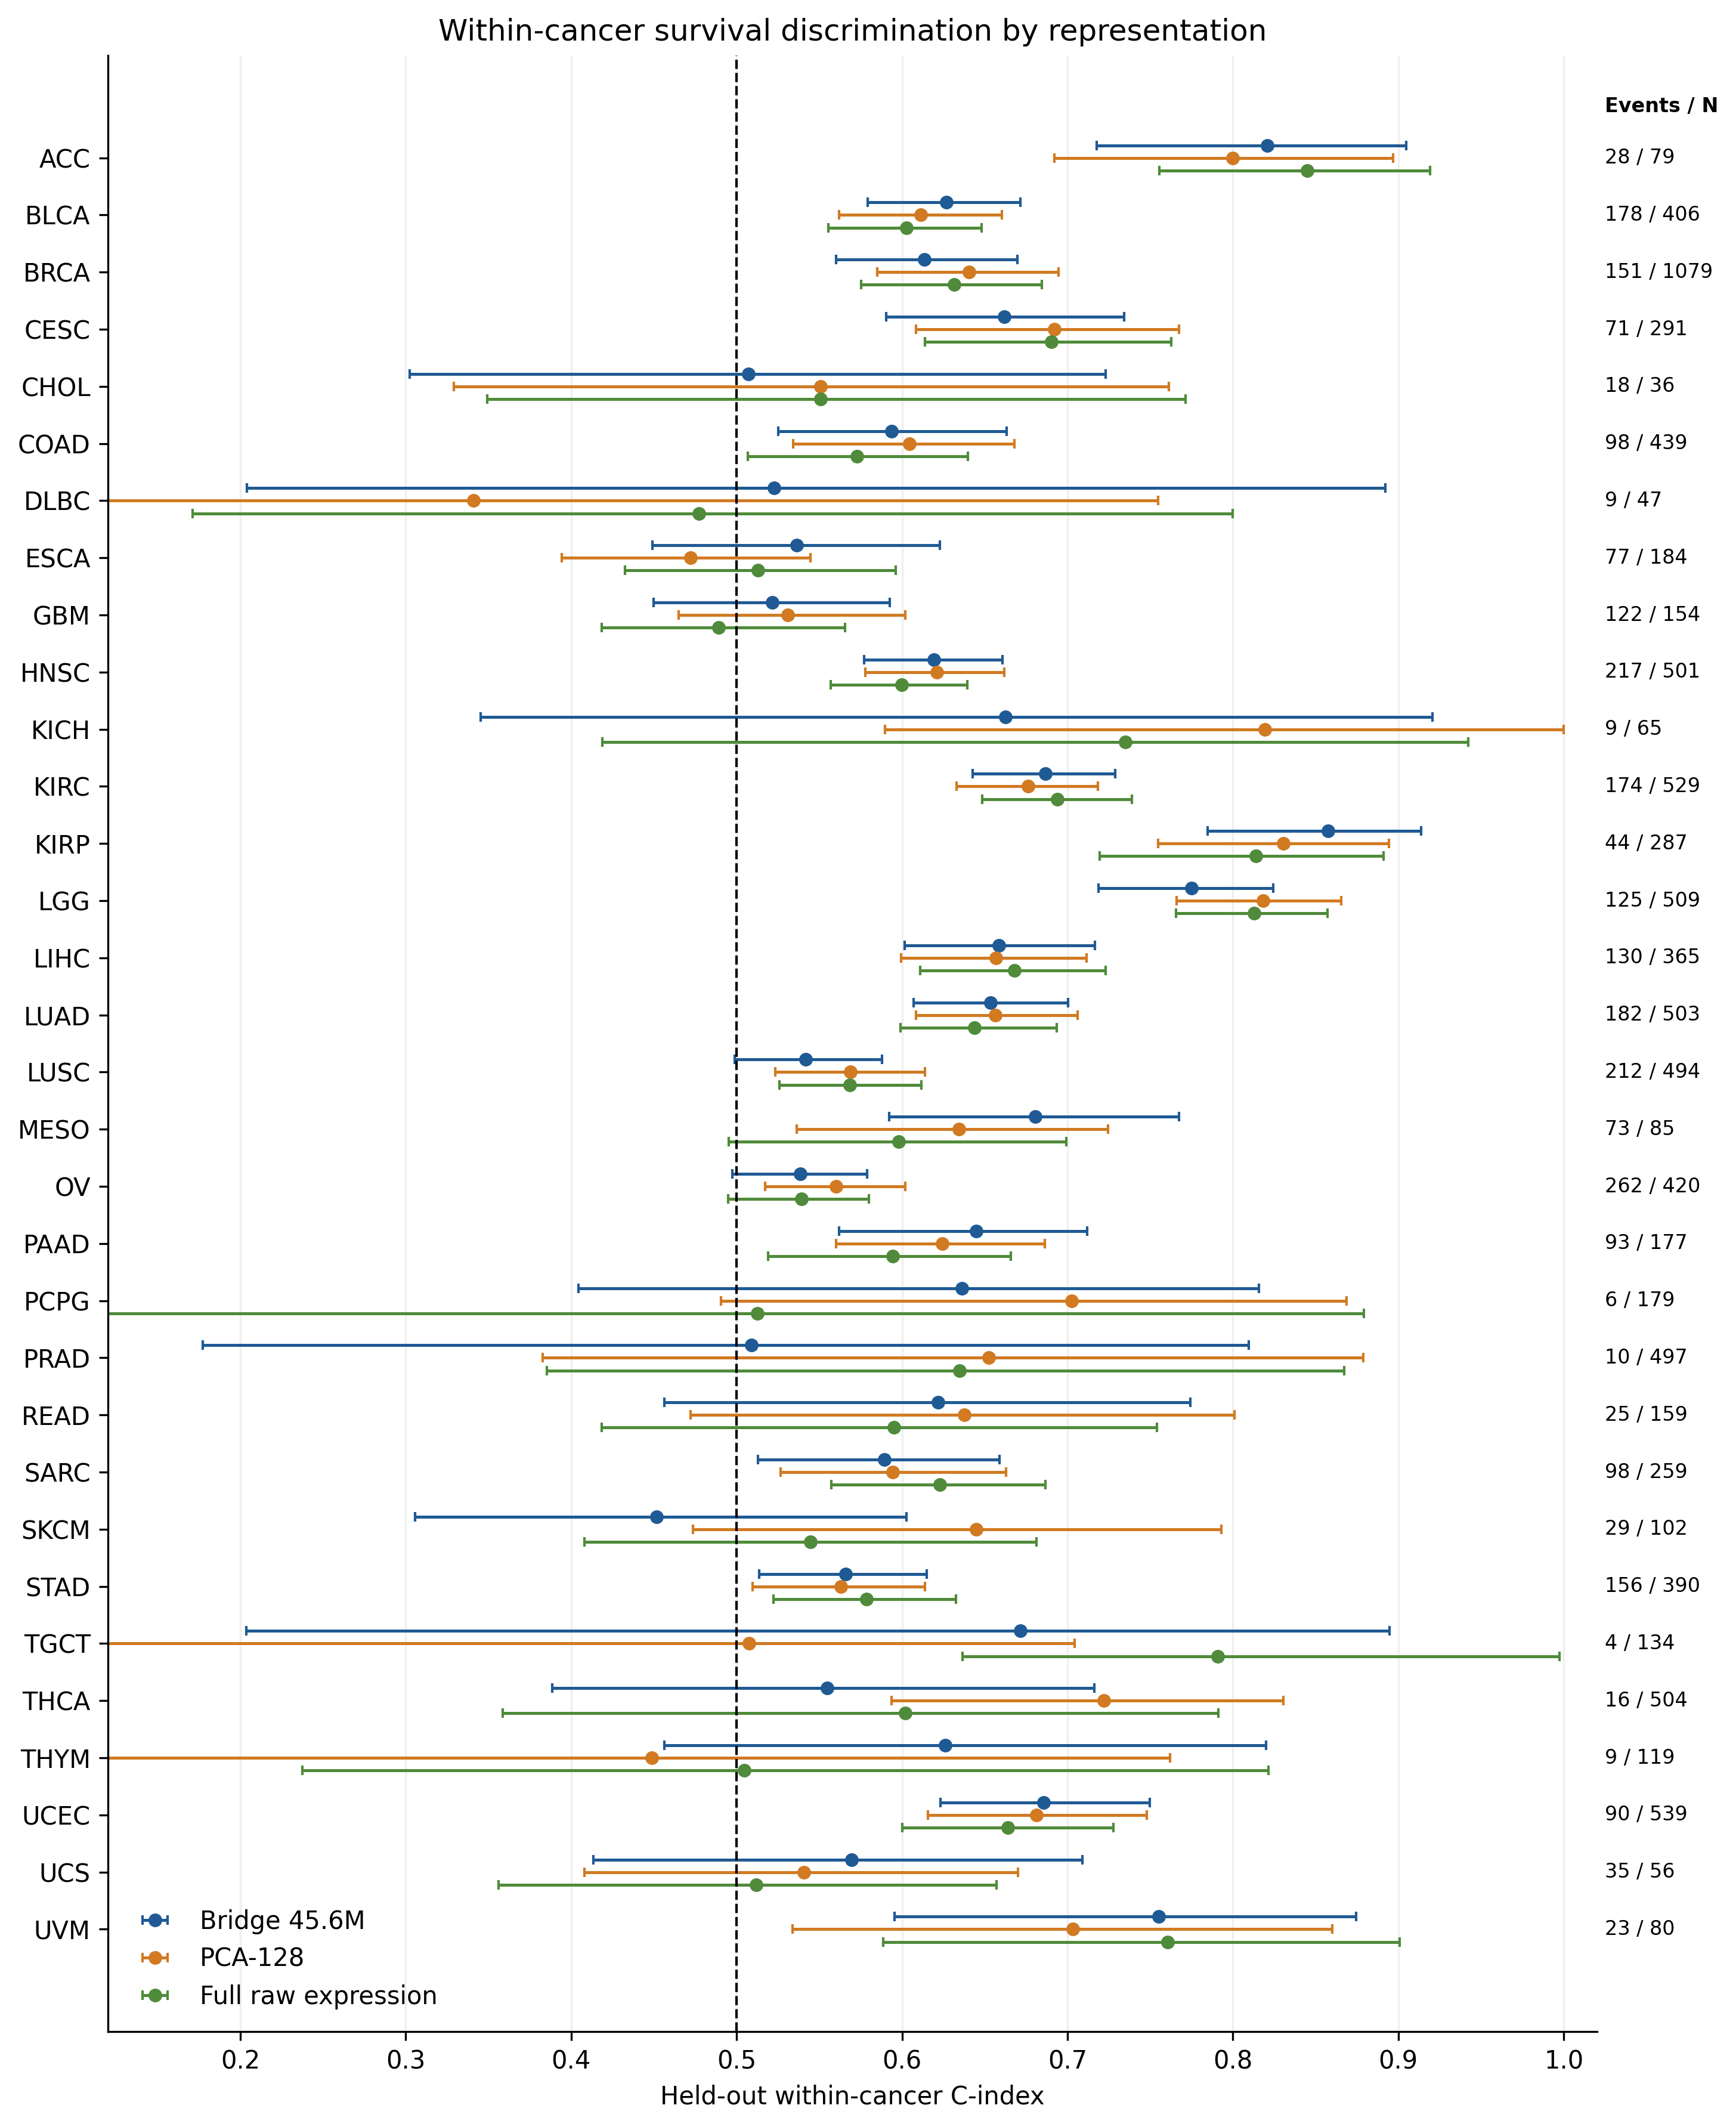

In [4]:
display(Image(filename=str(FIGURES / 'oof_survival_forest.png')))

In [5]:
per = pd.read_csv(CACHE / 'survival_5fold_oof_per_cancer.csv')
bridge = per[per.representation == 'Bridge 45.6M'].copy()
supported = bridge[(bridge.ci_low > 0.5) & (bridge.n_events >= 20)][['cancer','n_patients','n_events','c_index','ci_low','ci_high']]
display(supported.sort_values('c_index', ascending=False).round({'c_index':3,'ci_low':3,'ci_high':3}))

,cancer,n_patients,n_events,c_index,ci_low,ci_high
36,KIRP,287,44,0.858,0.785,0.914
0,ACC,79,28,0.821,0.718,0.905
39,LGG,509,125,0.775,0.719,0.824
93,UVM,80,23,0.755,0.596,0.874
33,KIRC,529,174,0.687,0.643,0.729
87,UCEC,539,90,0.686,0.623,0.750
51,MESO,85,73,0.680,0.592,0.767
9,CESC,291,71,0.662,0.590,0.734
42,LIHC,365,130,0.659,0.602,0.716
45,LUAD,503,182,0.654,0.607,0.701


Bridge has median within-cancer C-index **0.6239** and exceeds each conventional comparator in 15/32 cancers. Sparse events make several cancer-specific estimates uncertain; pointwise intervals are not multiplicity-adjusted discoveries.

## Literature context

Published frozen bulk-RNA embedding studies report pooled Cox C-indices of approximately **0.750–0.765**, placing Bridge's 0.7580–0.7589 in the same numerical range ([Gélard et al.](https://proceedings.mlr.press/v259/gelard25a.html); [multimodal survival study](https://arxiv.org/abs/2505.07683)). A separate scFoundation study found embedding performance comparable to raw expression under Ridge–Cox but better under Lasso–Cox, reinforcing that conclusions depend on the downstream estimator and regularization ([Liu et al.](https://pubmed.ncbi.nlm.nih.gov/41909608/)). These cross-study values are contextual, not directly paired.

## Limitations

TCGA is retrospective and no clinical covariates, calibration, external validation, or prospective testing are included. Event support is heterogeneous, pooled concordance can reflect between-cancer prognosis differences, and practical benefits of compression were not tested.

## Conclusion

A frozen 512-dimensional Bridge representation preserves substantial censoring-aware prognostic information. Complete OOF evaluation supports stable within-cancer discrimination in a subset of cancers but does not demonstrate systematic superiority over PCA-128 or full expression.